In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from prophet import Prophet

print("Python forecasting environment ready!")
print("Prophet version:", Prophet)

Importing plotly failed. Interactive plots will not work.


Python forecasting environment ready!
Prophet version: <class 'prophet.forecaster.Prophet'>


In [3]:
import sys
print(sys.executable)

c:\Users\RATHICK A\OneDrive\Desktop\DA_P2\Retail-Demand-Forecasting-Inventory-Optimization\.venv\Scripts\python.exe


In [4]:
import snowflake.connector
import pandas as pd

print("Snowflake connector ready!")

Snowflake connector ready!


In [5]:
from pathlib import Path

profile_path = Path.home() / ".dbt" / "profiles.yml"

print("dbt profile exists:", profile_path.exists())
print("Profile path:", profile_path)

dbt profile exists: True
Profile path: C:\Users\RATHICK A\.dbt\profiles.yml


In [6]:
from pathlib import Path

profile_path = Path.home() / ".dbt" / "profiles.yml"

print("dbt profile exists:", profile_path.exists())
print("Profile path:", profile_path)

dbt profile exists: True
Profile path: C:\Users\RATHICK A\.dbt\profiles.yml


In [7]:
from pathlib import Path
import yaml

profile_path = Path.home() / ".dbt" / "profiles.yml"

with open(profile_path, "r", encoding="utf-8") as file:
    profiles = yaml.safe_load(file)

print("Available dbt profiles:", list(profiles.keys()))

Available dbt profiles: ['retail_demand_dbt']


In [8]:
from pathlib import Path
import yaml
import snowflake.connector

# Read the existing dbt profile
profile_path = Path.home() / ".dbt" / "profiles.yml"

with open(profile_path, "r", encoding="utf-8") as file:
    profiles = yaml.safe_load(file)

profile = profiles["retail_demand_dbt"]
target_name = profile.get("target", "dev")
config = profile["outputs"][target_name].copy()

# Remove dbt-only configuration fields
for key in ["type", "threads", "query_tag", "connect_retries",
            "connect_timeout", "retry_on_database_errors",
            "retry_all", "reuse_connections"]:
    config.pop(key, None)

# Connect using the existing profile settings
conn = snowflake.connector.connect(**config)

# Verify the connection
cursor = conn.cursor()
try:
    cursor.execute("""
        SELECT CURRENT_DATABASE(), CURRENT_SCHEMA(), CURRENT_WAREHOUSE()
    """)
    print("Snowflake connection successful!")
    print("Database, schema, warehouse:", cursor.fetchone())
finally:
    cursor.close()

Snowflake connection successful!
Database, schema, warehouse: ('RETAIL_DEMAND', 'PUBLIC', 'COMPUTE_WH')


In [9]:

import pandas as pd

sales_id = "FOODS_3_586_TX_2_validation"

query = """
SELECT
    DS,
    Y,
    EVENT_NAME_1,
    EVENT_TYPE_1,
    EVENT_NAME_2,
    EVENT_TYPE_2
FROM RETAIL_DEMAND.PUBLIC.FORECASTING_PROPHET_DATA
WHERE SALES_ID = %(sales_id)s
ORDER BY DS
"""

df = pd.read_sql(
    query,
    conn,
    params={"sales_id": sales_id}
)

df["DS"] = pd.to_datetime(df["DS"])
df = df.sort_values("DS").reset_index(drop=True)

print("Product:", sales_id)
print("Rows:", len(df))
print("Date range:", df["DS"].min(), "to", df["DS"].max())
print("Missing dates:", df["DS"].diff().dropna().dt.days.ne(1).sum())
display(df.head())


C:\Users\RATHICK A\AppData\Local\Temp\ipykernel_26160\1590850707.py:18: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(


Product: FOODS_3_586_TX_2_validation
Rows: 1913
Date range: 2011-01-29 00:00:00 to 2016-04-24 00:00:00
Missing dates: 0


,DS,Y,EVENT_NAME_1,EVENT_TYPE_1,EVENT_NAME_2,EVENT_TYPE_2
0,2011-01-29,98,NaN,NaN,NaN,NaN
1,2011-01-30,85,NaN,NaN,NaN,NaN
2,2011-01-31,47,NaN,NaN,NaN,NaN
3,2011-02-01,56,NaN,NaN,NaN,NaN
4,2011-02-02,51,NaN,NaN,NaN,NaN


In [10]:

from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import matplotlib.pyplot as plt

# Prophet requires columns named ds (date) and y (target)
prophet_df = df[["DS", "Y"]].rename(
    columns={"DS": "ds", "Y": "y"}
).copy()

# Hold out the last 30 days for evaluation
horizon = 30
train = prophet_df.iloc[:-horizon].copy()
test = prophet_df.iloc[-horizon:].copy()

# Train the model using historical data only
model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False,
    interval_width=0.95
)

model.fit(train)

# Predict the held-out 30 days
future = test[["ds"]].copy()
forecast = model.predict(future)

# Compare predictions with actual sales
results = test.merge(
    forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]],
    on="ds"
)

results["yhat"] = results["yhat"].clip(lower=0)

mae = mean_absolute_error(results["y"], results["yhat"])
rmse = np.sqrt(mean_squared_error(results["y"], results["yhat"]))
wape = (
    np.abs(results["y"] - results["yhat"]).sum()
    / results["y"].sum()
) * 100

print(f"Training observations: {len(train)}")
print(f"Test observations: {len(test)}")
print(f"MAE:  {mae:.2f} units")
print(f"RMSE: {rmse:.2f} units")
print(f"WAPE: {wape:.2f}%")

display(results.head())


c:\Users\RATHICK A\OneDrive\Desktop\DA_P2\Retail-Demand-Forecasting-Inventory-Optimization\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
23:55:05 - cmdstanpy - INFO - Chain [1] start processing
23:55:07 - cmdstanpy - INFO - Chain [1] done processing


Training observations: 1883
Test observations: 30
MAE:  9.50 units
RMSE: 11.68 units
WAPE: 12.11%


,ds,y,yhat,yhat_lower,yhat_upper
0,2016-03-26,127,111.737121,71.828834,151.059799
1,2016-03-27,100,106.811796,69.406683,147.161280
2,2016-03-28,59,71.382386,32.053244,113.487982
3,2016-03-29,51,67.318851,26.547088,107.919690
4,2016-03-30,61,68.014536,27.360231,109.791709


,MAE,RMSE,WAPE (%)
Prophet,9.50,11.68,12.11
Seasonal Naive,11.73,14.09,14.95


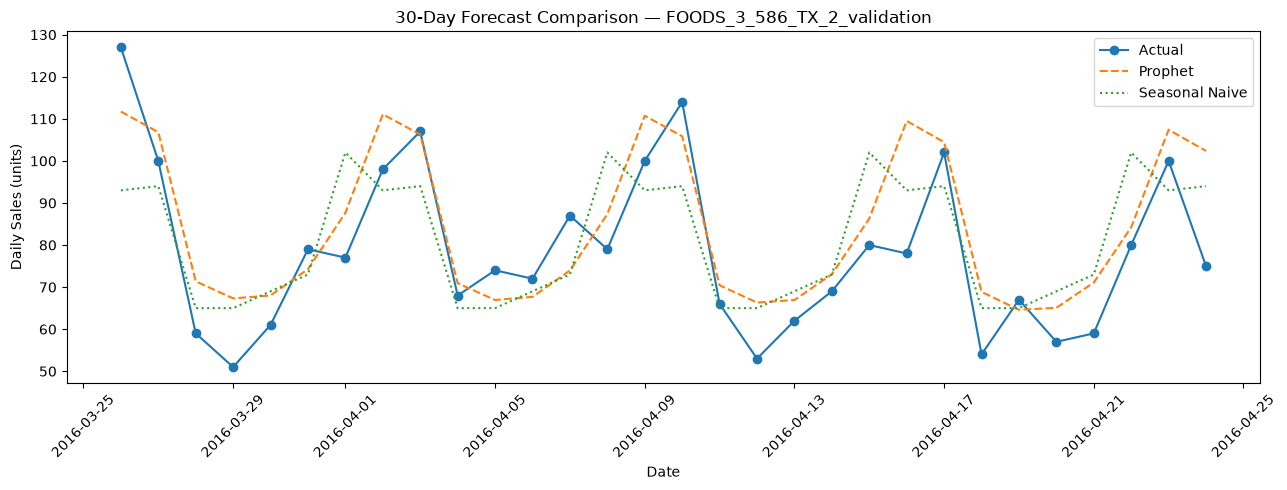

In [11]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Seasonal-naive forecast: repeat the final 7 training days
last_week = train["y"].tail(7).to_numpy()
naive_forecast = np.tile(
    last_week, int(np.ceil(len(test) / 7))
)[:len(test)]

actual = test["y"].to_numpy()
prophet_pred = results["yhat"].to_numpy()

def calculate_metrics(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "WAPE (%)": (
            np.abs(actual - predicted).sum() / actual.sum()
        ) * 100
    }

comparison = pd.DataFrame({
    "Prophet": calculate_metrics(actual, prophet_pred),
    "Seasonal Naive": calculate_metrics(actual, naive_forecast)
}).T

display(comparison.round(2))

# Visual comparison
plt.figure(figsize=(13, 5))
plt.plot(test["ds"], actual, label="Actual", marker="o")
plt.plot(test["ds"], prophet_pred, label="Prophet", linestyle="--")
plt.plot(test["ds"], naive_forecast, label="Seasonal Naive", linestyle=":")
plt.title(f"30-Day Forecast Comparison — {sales_id}")
plt.xlabel("Date")
plt.ylabel("Daily Sales (units)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [12]:

# Build a holiday/event calendar from the available data
event_cols = ["DS", "EVENT_NAME_1", "EVENT_NAME_2"]

events = df[event_cols].copy()
events["DS"] = pd.to_datetime(events["DS"])

event_frames = []

for col in ["EVENT_NAME_1", "EVENT_NAME_2"]:
    temp = events[["DS", col]].dropna().copy()
    temp.columns = ["ds", "holiday"]
    temp["holiday"] = temp["holiday"].astype(str)
    event_frames.append(temp)

holidays = pd.concat(event_frames, ignore_index=True).drop_duplicates()

print("Unique event dates:", holidays["ds"].nunique())
print("Event records:", len(holidays))
display(holidays.head(10))


Unique event dates: 154
Event records: 158


,ds,holiday
0,2011-02-06,SuperBowl
1,2011-02-14,ValentinesDay
2,2011-02-21,PresidentsDay
3,2011-03-09,LentStart
4,2011-03-16,LentWeek2
5,2011-03-17,StPatricksDay
6,2011-03-20,Purim End
7,2011-04-24,OrthodoxEaster
8,2011-04-26,Pesach End
9,2011-05-05,Cinco De Mayo


In [13]:

# Keep only events that occur in the training period
train_holidays = holidays[
    holidays["ds"].between(train["ds"].min(), train["ds"].max())
].copy()

# Fit Prophet with holiday effects
event_model = Prophet(
    holidays=train_holidays,
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False,
    interval_width=0.95
)

event_model.fit(train)

# Forecast the same 30-day test period
event_forecast = event_model.predict(test[["ds"]])

event_results = test.merge(
    event_forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]],
    on="ds"
)

event_results["yhat"] = event_results["yhat"].clip(lower=0)

# Compare the original model with the event-aware model
event_metrics = {
    "MAE": mean_absolute_error(
        event_results["y"], event_results["yhat"]
    ),
    "RMSE": np.sqrt(mean_squared_error(
        event_results["y"], event_results["yhat"]
    )),
    "WAPE (%)": (
        np.abs(event_results["y"] - event_results["yhat"]).sum()
        / event_results["y"].sum()
    ) * 100
}

comparison.loc["Prophet + Events"] = event_metrics
display(comparison.round(2))


23:57:16 - cmdstanpy - INFO - Chain [1] start processing
23:57:17 - cmdstanpy - INFO - Chain [1] done processing


,MAE,RMSE,WAPE (%)
Prophet,9.50,11.68,12.11
Seasonal Naive,11.73,14.09,14.95
Prophet + Events,9.58,11.81,12.21
